## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.


In [73]:
#Relevant dependencies
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker


**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK.

In [ ]:
# Importing data from Kagglehub
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\nicol\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [3]:
#Importing the dataset from the cache
files = os.listdir(path)
print("Files inside:", files)
#file_name = "uk-optimal-product-price-prediction.csv"
file_path = os.path.join(path,files[0])  # auto-pick file
df = pd.read_csv(file_path)

Files inside: ['amz_uk_price_prediction_dataset.csv']


## Data preview

 
The data contents are described as follows:

- **uid**: Unique identifier for each row. (type: int)
- **asin**: Product ID from Amazon. (type: str)
- **title**: Title of the product. (type: str)
- **stars**:Product rating. If 0, no ratings were found. (type: float)
- **reviews**:Number of customer reviews. If 0, no reviews were found. (type: int)
- **price**: Price of the product. (type: float, Currency: GBP)
- **isBestSeller**: Product category. (type: str)
- **boughtInLastMonth**: Whether the product had the Amazon BestSeller status or not. (type: bool)
- **category** : Indicates how many products we sold last month. (type: int)


In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [32]:
#Is there any missing data in the column? 
df["category"].isna().sum()

np.int64(0)

The data imported contains in total 9 columns, as indicated in the reference, with 2443651 entries. There is no missing data.

Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

Data column is complete

In [38]:
#Let's check the type of categories present by gathering them in a list and counting the frequency
all_listing_frequency= df.category.value_counts()#.rename_axis('category').reset_index(name='counts')
all_listing_percentage= (df.category.value_counts(normalize=True)*100)#.rename_axis('category').reset_index(name='percentage')
sample_category = pd.concat([all_listing_frequency,all_listing_percentage],axis=1)
sample_category.rename(columns={"count":"items_in_category","proportion":"percentage"})

,items_in_category,percentage
category,,
Sports & Outdoors,836265,34.221949
Beauty,19312,0.790293
"Handmade Clothing, Shoes & Accessories",19229,0.786896
Bath & Body,19092,0.781290
Birthday Gifts,18978,0.776625
...,...,...
Alexa Built-In Devices,107,0.004379
Motorbike Chassis,107,0.004379
Plugs,107,0.004379


The data shows 296 different product categories, where the main category is Sports& Outdoors with 836265 items registered accounting for a total of 34.2 %. This category is followed by Beauty and hygiene related categories in teh first positions with less than 1% of representation. 

The five main categories are:

In [40]:
#The function of value_counts already retrieves the data sorted as a descending list. This will become the main listing. 
main_listing_frequency = sample_category.iloc[0:5]
main_listing_frequency.rename(columns={"count":"items_in_category","proportion":"percentage"})

,items_in_category,percentage
category,,
Sports & Outdoors,836265,34.221949
Beauty,19312,0.790293
"Handmade Clothing, Shoes & Accessories",19229,0.786896
Bath & Body,19092,0.781290
Birthday Gifts,18978,0.776625


([0, 1, 2, 3, 4],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Beauty'),
  Text(2, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(3, 0, 'Bath & Body'),
  Text(4, 0, 'Birthday Gifts')])

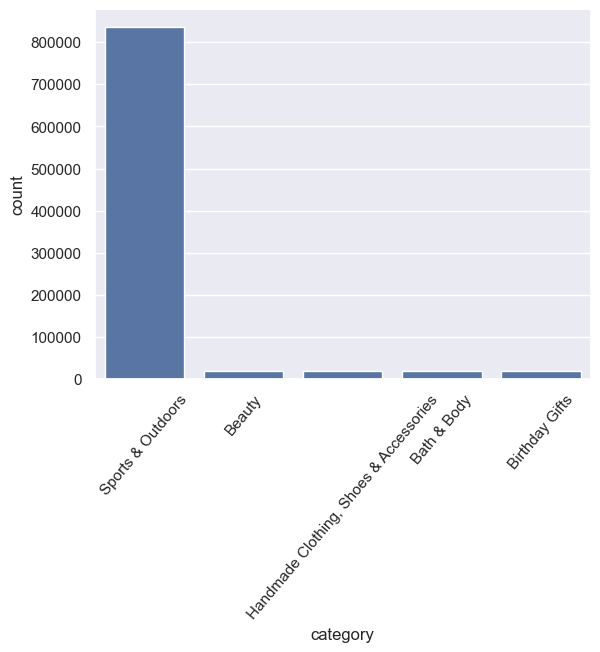

In [9]:
sns.set_theme()
sns.barplot(main_listing_frequency,
            x="category",
            y="count",          
            )
plt.xticks(rotation=50)

In [10]:
#Before showing the distribution as a pie chart, it is important to show the rest of the categories as "others"
remaining = 100-all_listing_percentage.iloc[0:5].sum()
others = {"others": remaining}
others = pd.Series(others)
new_listing_percentage = pd.concat([all_listing_percentage.iloc[0:5],others],axis = 0)
new_listing_percentage



Sports & Outdoors                         34.221949
Beauty                                     0.790293
Handmade Clothing, Shoes & Accessories     0.786896
Bath & Body                                0.781290
Birthday Gifts                             0.776625
others                                    62.642947
dtype: float64

<Axes: >

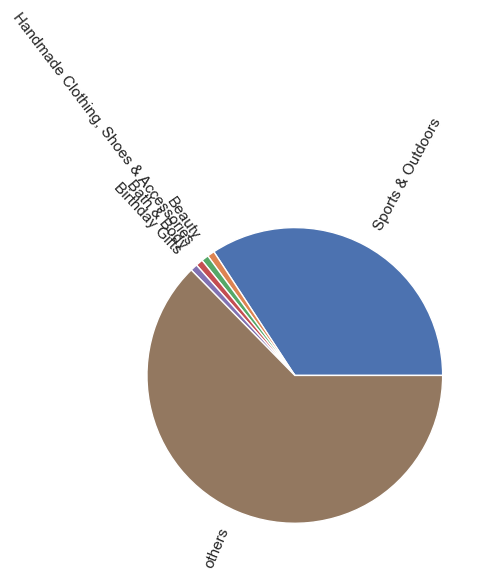

In [11]:
new_listing_percentage.plot.pie(rotatelabels=True)

while Sports and Outdoors appears as the main category in the listing, there is a 62% of products distributed amongst many other subcategories. No concrete conclusion may be made over this data set, the categories must be further reduced.

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

In [12]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [13]:
prices = df["price"]
round(prices.describe(),2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

Data overview shows that there is a high variance in the prices, while the maximum product can cost up to 100000(unit of coin), there are values with value of 0. Something that makes no sense because that would mean that the product is free. I will eliminate this values from the table.

In [14]:
#Check which products have a price of 0
condition = df["price"] == 0
no_price = df.loc[condition]
no_price

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
342871,367018,B07TYXW54L,Exercises with Resistance Loop Bands: 40+ Exer...,4.1,94,0.0,False,0,Sports & Outdoors
546823,589599,B003WL4O38,Operation Mincemeat: The True Spy Story that C...,4.5,5795,0.0,False,0,PC & Video Games
547321,590132,B005KKRRVK,Kensuke’s Kingdom,4.7,4565,0.0,False,0,PC & Video Games
547507,590332,B09WRXGQZL,"Faith, Hope and Carnage",4.7,546,0.0,False,0,PC & Video Games
794353,855945,B07T7L39TN,Never Split the Difference: Negotiating as if ...,4.6,39112,0.0,True,0,School & Educational Supplies
830446,905582,B00E3SYBWS,"Go for the Gold, Atalanta! (Myth-O-Mania Book 8)",4.7,190,0.0,False,0,Games & Game Accessories
830795,905932,B0BJQQZ79H,Battle of the Fang: Space Marine Battles: Warh...,4.6,166,0.0,False,0,Games & Game Accessories
833556,908772,B07YGP8442,100 Years of Leeds United,4.8,1349,0.0,False,0,Games & Game Accessories
836136,911439,B0BLFPRMZH,"Dungeons & Guardians: Battleborne, Book III",4.7,2421,0.0,False,0,Games & Game Accessories
1025782,1134431,B0BL8LQCHZ,"4 in 1 Bundle Off the Grid Survival Book, Prep...",4.3,5,0.0,False,0,Sports & Outdoors


1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [ ]:
mean_price = prices.mean()
median_price = prices.median()
mode_price = prices.mode()

print (f"Mean price:{mean_price} \nMedian price: {median_price} \nMode price: {mode_price}" )

Mean price:89.24380943923661 
 Median price: 19.09 
 Mode price: 0    9.99
Name: price, dtype: float64


The average price is much higher than the mode, which means that the distribution of price values is highly assymetrical. In terms of skewness, this would give a positive skewness.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [48]:
variance_price = prices.var()
std_price = prices.std()
range_price = prices.max()-prices.min()
Q1_price = prices.quantile(0.25)
Q3_price = prices.quantile(0.75)
IQR_price = Q3_price-Q1_price
print (f"Variance of prices:{variance_price} \n Standard deviation of price: {std_price} \n Range price: {range_price} \nInterquartile: {IQR_price}")

Variance of prices:119445.48532256528 
 Standard deviation of price: 345.60886175352226 
 Range price: 100000.0 
Interquartile: 36.0


The variance is in itself the measure of the dispersion of the values, which is significantly high. This is reflected in the high range of prices, from 0 to 100000. However the standard deviation is of 345.6, which means that there is presence of outliers. This is also clear by the IQR value that lies at 36, representing the 50% of all data is in this range.  

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [22]:
dist_prices = prices.value_counts()
dist_prices


price
9.99       48922
12.99      38823
8.99       34058
7.99       33632
14.99      32570
           ...  
2398.99        1
1453.08        1
1785.63        1
1347.36        1
317.34         1
Name: count, Length: 82916, dtype: int64

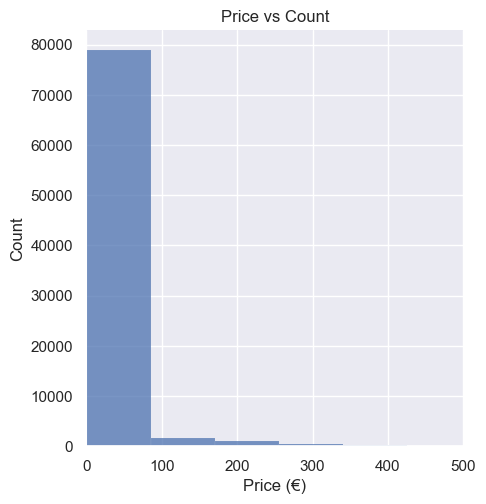

In [26]:
sns.displot(dist_prices)
plt.xlabel("Price (€)")
plt.ylabel("Count")
plt.title("Price vs Count")
plt.xlim(0,500)
plt.show()

Max value is not representative.

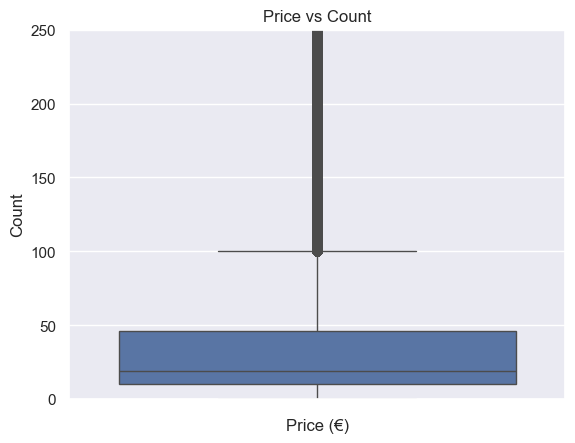

In [31]:
sns.boxplot(data=df["price"])
plt.xlabel("Price (€)")
plt.ylabel("Count")
plt.title("Price vs Count")
plt.ylim(0,250)
plt.show()

The Boxplot is shows for positive values only, as there is no expectation for negative values. From this graph, its clear that the outliers are individual items that have prices higher than 100. This will significantly affect the distribution of the data.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?


In [46]:
#Collecting data from ratings

ratings = df["stars"]
mean_ratings = ratings.mean()
median_ratings = ratings.median()
mode_ratings = ratings.mode()

print (f"Mean rating:{mean_ratings} \n Median rating: {median_ratings} \n Mode rating: {mode_ratings}")

Mean rating:2.152836472966066 
 Median rating: 0.0 
 Mode rating: 0    0.0
Name: stars, dtype: float64


There appears to be a negative rating for most of the products in the listing. 

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [50]:
variance_ratings = ratings.var()
std_rating  = ratings.std()
Q1_rating = ratings.quantile(0.25)
Q3_rating = ratings.quantile(0.75)
IQR_rating = Q3_rating-Q1_rating
print (f"Variance of prices:{variance_ratings} \nStandard deviation of price: {std_rating}  \nInterquartile: {IQR_rating}")

Variance of prices:4.81743402976196 
Standard deviation of price: 2.1948653785054697  
Interquartile: 4.4


There is a wide variation in customer feedback, while most of the califications for the products are around 4.4, the variance is significant.

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [54]:
print (f" Skewness:{round(ratings.skew(),2)} and Kurtosis:{round(ratings.kurt(),2)}")

 Skewness:0.08 and Kurtosis:-1.93


Skewness shows that the majority of the values are closer to the average value. The kurtosis index gives more information about the shape of the distribution of the values. The negative value indicates that indicates a flat shape of the distribution.  

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [59]:
freq_ratings = ratings.value_counts().rename_axis("stars").reset_index()
freq_ratings

,stars,count
0,0.0,1225641
1,4.5,151577
2,4.6,136995
3,4.4,136165
4,5.0,128492
5,4.3,112564
6,4.7,94566
7,4.2,86871
8,4.0,66089
9,4.1,65115


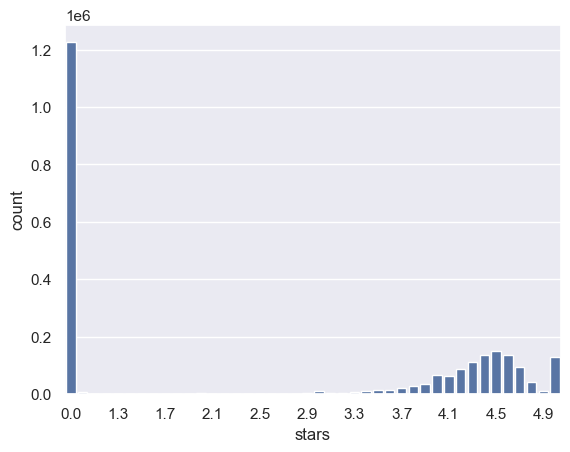

In [80]:
ax= sns.barplot(data=freq_ratings, x="stars",y="count")
ax.xaxis.set_major_locator(ticker.MultipleLocator(4))
plt.show()
